In [1]:

import sys
import importlib.util

print("Python version:", sys.version)

# Check package availability
packages = ["torch", "transformers", "datasets", "accelerate"]

print("\nPackage availability:")

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if available else 'Not installed'}")

# Check PyTorch and Apple Silicon MPS
if importlib.util.find_spec("torch") is not None:
    import torch

    print("\nPyTorch version:", torch.__version__)
    print("MPS built:", torch.backends.mps.is_built())
    print("MPS available:", torch.backends.mps.is_available())


Python version: 3.12.10 (v3.12.10:0cc81280367, Apr  8 2025, 08:46:59) [Clang 13.0.0 (clang-1300.0.29.30)]

Package availability:
torch: Not installed
transformers: Not installed
datasets: Not installed
accelerate: Not installed


In [2]:
import torch
import transformers

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)

print("MPS built:", torch.backends.mps.is_built())
print("MPS available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using Apple Silicon GPU")
else:
    device = torch.device("cpu")
    print("Using CPU")

PyTorch version: 2.15.0
Transformers version: 5.22.1
MPS built: True
MPS available: True
Using Apple Silicon GPU


In [3]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("Tokenizer loaded successfully.")
print("Model loaded successfully.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

W1103 18:07:34.195000 42013 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tokenizer loaded successfully.
Model loaded successfully.


In [4]:
# Move the model to Apple Silicon GPU
model = model.to(device)

# Count model parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Model:", model_name)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Model device:", next(model.parameters()).device)

Model: distilbert-base-uncased
Total parameters: 66,955,010
Trainable parameters: 66,955,010
Model device: mps:0


In [6]:
import pandas as pd

# Load the dataset
data_path = "data/raw/train.csv.gz"
df = pd.read_csv(data_path)

# Keep only the required columns
df = df[["comment_text", "toxic"]].copy()

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["toxic"].value_counts())

print("\nFirst 5 comments:")
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/train.csv.gz'

In [7]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in data folder:")
print(os.listdir("data"))

print("\nFiles in data/raw folder:")
if os.path.exists("data/raw"):
    print(os.listdir("data/raw"))
else:
    print("data/raw folder does not exist")

Current working directory:
/Users/ericshin/Documents/text-classification-content-moderation/notebooks

Files in data folder:


FileNotFoundError: [Errno 2] No such file or directory: 'data'

In [8]:
import os

data_path = "../data/raw/train.csv.gz"

print("File exists:", os.path.exists(data_path))
print("Absolute path:", os.path.abspath(data_path))

File exists: True
Absolute path: /Users/ericshin/Documents/text-classification-content-moderation/data/raw/train.csv.gz


In [9]:
import pandas as pd

df = pd.read_csv(data_path)
df = df[["comment_text", "toxic"]].copy()

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["toxic"].value_counts())

display(df.head())

Dataset shape: (159571, 2)

Missing values:
comment_text    0
toxic           0
dtype: int64

Class distribution:
toxic
0    144277
1     15294
Name: count, dtype: int64


,comment_text,toxic
0,Explanation\nWhy the edits made under my usern...,0
1,D'aww! He matches this background colour I'm s...,0
2,"Hey man, I'm really not trying to edit war. It...",0
3,"""\nMore\nI can't make any real suggestions on ...",0
4,"You, sir, are my hero. Any chance you remember...",0


In [10]:
from sklearn.model_selection import train_test_split

# Separate features and labels
X = df["comment_text"]
y = df["toxic"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 127656
Testing samples: 31915

Training class distribution:
toxic
0    115421
1     12235
Name: count, dtype: int64

Testing class distribution:
toxic
0    28856
1     3059
Name: count, dtype: int64


In [11]:
# Select 5 sample comments
sample_texts = X_train.iloc[:5].tolist()

# Tokenize the sample texts
sample_encoding = tokenizer(
    sample_texts,
    truncation=True,
    padding=True,
    max_length=128,
    return_tensors="pt"
)

print("Input IDs shape:", sample_encoding["input_ids"].shape)
print("Attention Mask shape:", sample_encoding["attention_mask"].shape)

print("\nFirst comment:")
print(sample_texts[0])

print("\nToken IDs:")
print(sample_encoding["input_ids"][0])

print("\nAttention Mask:")
print(sample_encoding["attention_mask"][0])

Input IDs shape: torch.Size([5, 80])
Attention Mask shape: torch.Size([5, 80])

First comment:
And more unfounded personal attacks by  here at Beeblebroxe's talk page. It just gets better and better. I suppose I am to blame for that conduct as well. Its somehow my fault I guess.

Token IDs:
tensor([  101,  1998,  2062,  4895, 21001,  3167,  4491,  2011,  2182,  2012,
        10506,  3468, 12618,  2595,  2063,  1005,  1055,  2831,  3931,  1012,
         2009,  2074,  4152,  2488,  1998,  2488,  1012,  1045,  6814,  1045,
         2572,  2000,  7499,  2005,  2008,  6204,  2004,  2092,  1012,  2049,
         5064,  2026,  6346,  1045,  3984,  1012,   102,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0])

Attention Mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1

In [12]:
import torch
from torch.utils.data import Dataset, DataLoader


# Create a custom Dataset
class ToxicCommentDataset(Dataset):

    def __init__(self, texts, labels):
        self.texts = list(texts)
        self.labels = list(labels)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx], int(self.labels[idx])


# Create a function for batch tokenization
def collate_batch(batch):

    texts, labels = zip(*batch)

    encoding = tokenizer(
        list(texts),
        truncation=True,
        padding=True,
        max_length=128,
        return_tensors="pt"
    )

    encoding["labels"] = torch.tensor(
        labels,
        dtype=torch.long
    )

    return encoding


# Create datasets
train_dataset = ToxicCommentDataset(X_train, y_train)
test_dataset = ToxicCommentDataset(X_test, y_test)


# Create DataLoaders
batch_size = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0
)


print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))
print("Batch size:", batch_size)

Training dataset: 127656
Testing dataset: 31915
Batch size: 8


In [13]:
# Get one batch from the training DataLoader
batch = next(iter(train_loader))

# Inspect batch information
print("Input IDs shape:", batch["input_ids"].shape)
print("Attention Mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)

print("\nData types:")
print("Input IDs:", batch["input_ids"].dtype)
print("Attention Mask:", batch["attention_mask"].dtype)
print("Labels:", batch["labels"].dtype)

print("\nLabels:")
print(batch["labels"])

print("\nFirst comment token length:")
print(batch["attention_mask"][0].sum().item())

Input IDs shape: torch.Size([8, 100])
Attention Mask shape: torch.Size([8, 100])
Labels shape: torch.Size([8])

Data types:
Input IDs: torch.int64
Attention Mask: torch.int64
Labels: torch.int64

Labels:
tensor([0, 1, 0, 0, 0, 0, 0, 0])

First comment token length:
62


In [14]:
from sklearn.model_selection import train_test_split

# Split training data into training and validation sets
X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train_fit))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train_fit.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

Training samples: 114890
Validation samples: 12766
Testing samples: 31915

Training class distribution:
toxic
0    103879
1     11011
Name: count, dtype: int64

Validation class distribution:
toxic
0    11542
1     1224
Name: count, dtype: int64


In [15]:
from torch.utils.data import DataLoader

# Create three datasets
train_dataset = ToxicCommentDataset(X_train_fit, y_train_fit)
val_dataset = ToxicCommentDataset(X_val, y_val)
test_dataset = ToxicCommentDataset(X_test, y_test)

# Set batch size
batch_size = 8

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 14362
Validation batches: 1596
Testing batches: 3990


In [16]:
import torch
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Training configuration
num_epochs = 2
learning_rate = 2e-5
weight_decay = 0.01

# Calculate training steps
total_training_steps = len(train_loader) * num_epochs
warmup_steps = int(0.1 * total_training_steps)

# Loss function
criterion = torch.nn.CrossEntropyLoss()

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

# Learning rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Epochs:", num_epochs)
print("Learning rate:", learning_rate)
print("Weight decay:", weight_decay)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)
print("Optimizer:", type(optimizer).__name__)
print("Loss function:", type(criterion).__name__)

Epochs: 2
Learning rate: 2e-05
Weight decay: 0.01
Total training steps: 28724
Warmup steps: 2872
Optimizer: AdamW
Loss function: CrossEntropyLoss


In [17]:
# Get one batch
batch = next(iter(train_loader))

# Set model to evaluation mode
model.eval()

# Move batch to MPS
input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

# Forward pass
with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss
    logits = outputs.logits

print("Device:", device)
print("Logits shape:", logits.shape)
print("Loss:", loss.item())
print("Predicted classes:", torch.argmax(logits, dim=1))
print("Actual labels:", labels)

Device: mps
Logits shape: torch.Size([8, 2])
Loss: 0.7620580196380615
Predicted classes: tensor([1, 1, 1, 1, 1, 1, 1, 1], device='mps:0')
Actual labels: tensor([0, 0, 0, 0, 0, 0, 1, 0], device='mps:0')


In [18]:
# Get one training batch
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

# Set model to training mode
model.train()

# Clear previous gradients
optimizer.zero_grad()

# Forward pass
outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    labels=labels
)

loss = outputs.loss

# Backward propagation
loss.backward()

# Check gradients
grad = model.classifier.weight.grad

print("Loss:", loss.item())
print("Gradient exists:", grad is not None)
print("Gradient shape:", grad.shape)
print("Gradient is finite:", torch.isfinite(grad).all().item())

# Clear gradients without updating parameters
optimizer.zero_grad(set_to_none=True)

# Return to evaluation mode
model.eval()

Loss: 0.8148016333580017
Gradient exists: True
Gradient shape: torch.Size([2, 768])
Gradient is finite: True


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [19]:
import time
import torch

# Set model to training mode
model.train()

# Prepare data iterator
benchmark_loader = iter(train_loader)

# Warm-up: 5 batches
for i in range(5):
    batch = next(benchmark_loader)

    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    optimizer.zero_grad(set_to_none=True)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    outputs.loss.backward()

# Synchronize GPU before timing
torch.mps.synchronize()

# Benchmark: 50 batches
num_benchmark_batches = 50
benchmark_losses = []

start_time = time.perf_counter()

for i in range(num_benchmark_batches):
    batch = next(benchmark_loader)

    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    optimizer.zero_grad(set_to_none=True)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss
    loss.backward()

    benchmark_losses.append(loss.item())

torch.mps.synchronize()

end_time = time.perf_counter()

# Clear gradients
optimizer.zero_grad(set_to_none=True)

# Calculate performance
elapsed_time = end_time - start_time
average_batch_time = elapsed_time / num_benchmark_batches
estimated_epoch_time = average_batch_time * len(train_loader)

print("Benchmark batches:", num_benchmark_batches)
print("Total benchmark time:", round(elapsed_time, 2), "seconds")
print("Average batch time:", round(average_batch_time, 3), "seconds")
print("Average loss:", round(sum(benchmark_losses) / len(benchmark_losses), 4))
print("Estimated one epoch time:", round(estimated_epoch_time / 60, 2), "minutes")

# Return model to evaluation mode
model.eval()

Benchmark batches: 50
Total benchmark time: 7.12 seconds
Average batch time: 0.142 seconds
Average loss: 0.7749
Estimated one epoch time: 34.08 minutes


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [20]:
import time
from tqdm.auto import tqdm

num_epochs = 2
best_val_loss = float("inf")

training_history = []

for epoch in range(num_epochs):

    print(f"\n{'=' * 50}")
    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"{'=' * 50}")

    # Training
    model.train()

    total_train_loss = 0

    train_progress = tqdm(train_loader, desc="Training")

    for batch in train_progress:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()

        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()

        train_progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = total_train_loss / len(train_loader)

    # Validation
    model.eval()

    total_val_loss = 0

    with torch.no_grad():

        val_progress = tqdm(val_loader, desc="Validation")

        for batch in val_progress:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_val_loss += outputs.loss.item()

    avg_val_loss = total_val_loss / len(val_loader)

    # Record results
    training_history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss
    })

    print(f"\nEpoch {epoch + 1} Results")
    print(f"Training Loss: {avg_train_loss:.4f}")
    print(f"Validation Loss: {avg_val_loss:.4f}")

    # Save best model
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "../results/distilbert_best_model.pt"
        )

        print("Best model saved!")

print("\nTraining completed.")


Epoch 1/2


Training:   0%|          | 0/14362 [00:00<?, ?it/s]

Validation:   0%|          | 0/1596 [00:00<?, ?it/s]


Epoch 1 Results
Training Loss: 0.1098
Validation Loss: 0.0860
Best model saved!

Epoch 2/2


Training:   0%|          | 0/14362 [00:00<?, ?it/s]

Validation:   0%|          | 0/1596 [00:00<?, ?it/s]


Epoch 2 Results
Training Loss: 0.0575
Validation Loss: 0.0860
Best model saved!

Training completed.


In [21]:
# Load the best saved model

model.load_state_dict(
    torch.load(
        "../results/distilbert_best_model.pt",
        map_location=device
    )
)

model.to(device)
model.eval()

print("Best model loaded successfully.")
print("Evaluation device:", device)

Best model loaded successfully.
Evaluation device: mps


In [22]:
import numpy as np
from tqdm.auto import tqdm

all_predictions = []
all_probabilities = []
all_labels = []

model.eval()

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Testing"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

print("Testing completed.")
print("Number of predictions:", len(y_pred))
print("Prediction probabilities:", y_prob[:10])
print("Predicted labels:", y_pred[:10])

Testing:   0%|          | 0/3990 [00:00<?, ?it/s]

Testing completed.
Number of predictions: 31915
Prediction probabilities: [8.3696789e-01 3.4834514e-04 2.3264048e-04 8.8349357e-04 9.1726892e-05
 1.1914520e-04 6.1652163e-04 1.4272158e-04 3.0150186e-04 6.8310463e-01]
Predicted labels: [1 0 0 0 0 0 0 0 0 1]


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(y_true, y_pred)

recall = recall_score(y_true, y_pred)

f1 = f1_score(y_true, y_pred)

roc_auc = roc_auc_score(y_true, y_prob)

average_precision = average_precision_score(
    y_true,
    y_prob
)

print("DistilBERT Evaluation Results")
print("=" * 40)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Precision:         {precision:.4f}")
print(f"Recall:            {recall:.4f}")
print(f"F1-score:          {f1:.4f}")
print(f"ROC-AUC:           {roc_auc:.4f}")
print(f"Average Precision: {average_precision:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

DistilBERT Evaluation Results
Accuracy:          0.9698
Precision:         0.8440
Recall:            0.8401
F1-score:          0.8421
ROC-AUC:           0.9874
Average Precision: 0.9243

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     28856
           1       0.84      0.84      0.84      3059

    accuracy                           0.97     31915
   macro avg       0.91      0.91      0.91     31915
weighted avg       0.97      0.97      0.97     31915


Confusion Matrix:
[[28381   475]
 [  489  2570]]


In [24]:
import pandas as pd
import os

# Create metrics dictionary
distilbert_metrics = {
    "Model": "DistilBERT",
    "Training_Samples": len(train_dataset),
    "Testing_Samples": len(test_dataset),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "Average_Precision": average_precision
}

# Convert to DataFrame
distilbert_df = pd.DataFrame([distilbert_metrics])

# Save results
output_path = "../results/metrics/distilbert_metrics.csv"

distilbert_df.to_csv(output_path, index=False)

print("DistilBERT metrics saved successfully.")
display(distilbert_df)

DistilBERT metrics saved successfully.


,Model,Training_Samples,Testing_Samples,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
0,DistilBERT,114890,31915,0.969795,0.844007,0.840144,0.842071,0.987414,0.924325


In [25]:
# Load metrics from all three models

baseline_df = pd.read_csv(
    "../results/metrics/baseline_metrics.csv"
)

word2vec_df = pd.read_csv(
    "../results/metrics/word2vec_metrics.csv"
)

distilbert_df = pd.read_csv(
    "../results/metrics/distilbert_metrics.csv"
)

# Combine all results

model_comparison = pd.concat(
    [baseline_df, word2vec_df, distilbert_df],
    ignore_index=True
)

# Select important metrics

comparison_table = model_comparison[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC"
    ]
].copy()

# Display comparison

display(
    comparison_table.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}"
    })
)

# Save comparison

comparison_table.to_csv(
    "../results/metrics/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,TF-IDF + Logistic Regression,0.9423,0.6506,0.8594,nan,0.9730
1,Word2Vec + Logistic Regression,0.9434,0.8076,0.5378,nan,0.9477
2,DistilBERT,0.9698,0.8440,0.8401,0.8421,0.9874


Model comparison saved successfully.


In [26]:
print("TF-IDF columns:")
print(baseline_df.columns.tolist())

print("\nWord2Vec columns:")
print(word2vec_df.columns.tolist())

print("\nDistilBERT columns:")
print(distilbert_df.columns.tolist())

TF-IDF columns:
['Model', 'Training_Samples', 'Testing_Samples', 'TFIDF_Features', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'Average_Precision']

Word2Vec columns:
['Model', 'Training_Samples', 'Testing_Samples', 'Embedding_Dimension', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']

DistilBERT columns:
['Model', 'Training_Samples', 'Testing_Samples', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'Average_Precision']


In [27]:
# Standardize F1 column names
baseline_df = baseline_df.rename(
    columns={"F1_Score": "F1"}
)

word2vec_df = word2vec_df.rename(
    columns={"F1_Score": "F1"}
)

print("TF-IDF F1:", baseline_df["F1"].iloc[0])
print("Word2Vec F1:", word2vec_df["F1"].iloc[0])
print("DistilBERT F1:", distilbert_df["F1"].iloc[0])

TF-IDF F1: 0.7405633802816901
Word2Vec F1: 0.6456043956043956
DistilBERT F1: 0.8420707732634338


In [28]:
# Combine model results
model_comparison_df = pd.concat(
    [baseline_df, word2vec_df, distilbert_df],
    ignore_index=True
)

# Select common evaluation metrics
model_comparison_df = model_comparison_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC"
    ]
]

display(model_comparison_df)

# Save updated comparison
model_comparison_df.to_csv(
    "../results/metrics/model_comparison.csv",
    index=False
)

print("Model comparison updated successfully.")

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,TF-IDF + Logistic Regression,0.942284,0.650582,0.859431,0.740563,0.973032
1,Word2Vec + Logistic Regression,0.943412,0.807560,0.537757,0.645604,0.947712
2,DistilBERT,0.969795,0.844007,0.840144,0.842071,0.987414


Model comparison updated successfully.


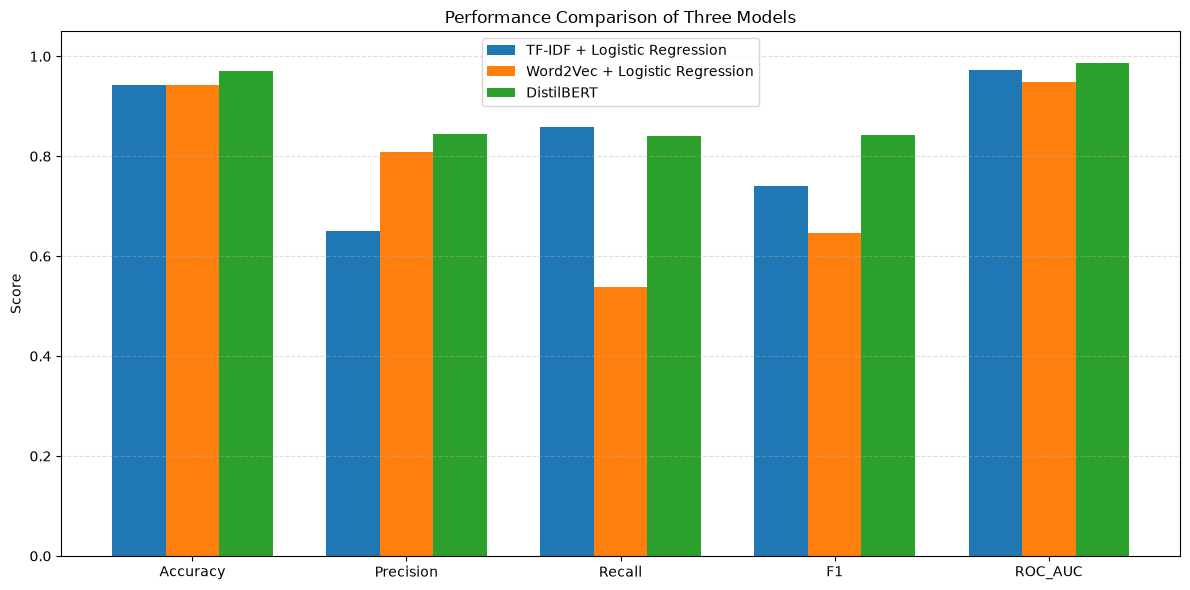

Updated comparison figure saved successfully.


In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics for comparison
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]

models = model_comparison_df["Model"].tolist()

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for i, model in enumerate(models):
    values = model_comparison_df.loc[
        model_comparison_df["Model"] == model,
        metrics
    ].values.flatten()

    ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=model
    )

ax.set_ylabel("Score")
ax.set_title("Performance Comparison of Three Models")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "../results/figures/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Updated comparison figure saved successfully.")

## Model Comparison and Discussion

Three machine learning approaches were evaluated for toxic comment classification: TF-IDF with Logistic Regression, Word2Vec with Logistic Regression, and DistilBERT.

The results show that DistilBERT achieved the best overall performance, with an F1-score of 0.8421 and a ROC-AUC of 0.9874. It also achieved the highest accuracy (0.9698) and precision (0.8440). These results suggest that the contextual representations learned by transformer-based models are effective for identifying toxic comments.

TF-IDF achieved the highest recall of 0.8594, outperforming the other two models in identifying positive toxic samples. However, its precision was lower (0.6506), indicating a higher proportion of false positive predictions.

Word2Vec achieved a precision of 0.8076 but a relatively low recall of 0.5378. This suggests that its averaged word embeddings were less effective at capturing the linguistic patterns required for toxic comment detection.

Overall, DistilBERT provided the best balance between precision and recall. TF-IDF remained competitive, particularly in recall, while Word2Vec showed comparatively weaker performance.

It should be noted that DistilBERT was trained using a smaller training subset because a validation set was reserved for model selection. Therefore, differences in training sample sizes should be considered when interpreting the comparison.


In [30]:
print("X_test type:", type(X_test))
print("X_test length:", len(X_test))

print("y_true length:", len(y_true))
print("y_pred length:", len(y_pred))

print("\nFirst 3 test comments:")
print(X_test.iloc[:3] if hasattr(X_test, "iloc") else X_test[:3])

print("\nActual labels:", y_true[:3])
print("Predicted labels:", y_pred[:3])

X_test type: <class 'pandas.Series'>
X_test length: 31915
y_true length: 31915
y_pred length: 31915

First 3 test comments:
157874    "\n""oo9"", if you have ANY actual evidence, s...
106494    It seems that AE defend anything - including v...
159283    Don Patch's Parents and Childhood ==\n\nI thin...
Name: comment_text, dtype: str

Actual labels: [0 0 0]
Predicted labels: [1 0 0]


In [31]:
import numpy as np
import pandas as pd

# Convert labels to NumPy arrays
y_true_array = np.asarray(y_true)
y_pred_array = np.asarray(y_pred)

# Find misclassified sample positions
fp_indices = np.where(
    (y_true_array == 0) & (y_pred_array == 1)
)[0]

fn_indices = np.where(
    (y_true_array == 1) & (y_pred_array == 0)
)[0]

print("False Positives:", len(fp_indices))
print("False Negatives:", len(fn_indices))

# Extract 5 examples from each category
fp_examples = pd.DataFrame({
    "Comment": X_test.iloc[fp_indices[:5]].values,
    "Actual": y_true_array[fp_indices[:5]],
    "Predicted": y_pred_array[fp_indices[:5]]
})

fn_examples = pd.DataFrame({
    "Comment": X_test.iloc[fn_indices[:5]].values,
    "Actual": y_true_array[fn_indices[:5]],
    "Predicted": y_pred_array[fn_indices[:5]]
})

print("\n===== False Positive Examples =====")
display(fp_examples)

print("\n===== False Negative Examples =====")
display(fn_examples)

False Positives: 475
False Negatives: 489

===== False Positive Examples =====


,Comment,Actual,Predicted
0,"""\n""""oo9"""", if you have ANY actual evidence, s...",0,1
1,But then he wouldn't be able to sit here argui...,0,1
2,"""\n i didn't sign anything or agree to anythin...",0,1
3,Tommy Doom\nsome idiot put Tommy Doom instead ...,0,1
4,and when i done popin 17 1/2 capp in yo black ...,0,1



===== False Negative Examples =====


,Comment,Actual,Predicted
0,""")\n\nTrumpet, I certainly will let someone wh...",1,0
1,Please look at this guy's talk history. He sta...,1,0
2,No silly it isnt ITS UR MOMS and might I say q...,1,0
3,""" \n\nfor example, if i were to say that you a...",1,0
4,Pffft... that's your interpretation. I do give...,1,0


### Error Analysis

To better understand the classification performance of DistilBERT, false positive and false negative predictions were examined.

The model produced 475 false positives and 489 false negatives on the test set.

**False Positives:** Some non-toxic comments were incorrectly classified as toxic. These cases may involve informal language, unusual spelling, ambiguous expressions, or context-dependent wording.

**False Negatives:** Some toxic comments were incorrectly classified as non-toxic. This suggests that certain harmful expressions may be difficult to identify without considering their broader linguistic context.

**Discussion:** Although DistilBERT achieved strong overall performance, these classification errors demonstrate that automated content moderation is not perfect. In practical applications, false positives may lead to unnecessarily restricting legitimate comments, while false negatives may allow harmful content to remain visible. Therefore, the choice of classification threshold should consider the trade-off between precision and recall.

In [32]:
import os

folders = [
    "../results/metrics",
    "../results/figures"
]

for folder in folders:
    print(f"\n===== {folder} =====")

    for filename in sorted(os.listdir(folder)):
        print(filename)


===== ../results/metrics =====
baseline_metrics.csv
distilbert_metrics.csv
model_comparison.csv
threshold_comparison.csv
word2vec_metrics.csv
word2vec_threshold_comparison.csv

===== ../results/figures =====
baseline_pr_curve.png
baseline_roc_curve.png
model_performance_comparison.png
word2vec_confusion_matrix.png
word2vec_pr_curve.png
word2vec_roc_curve.png


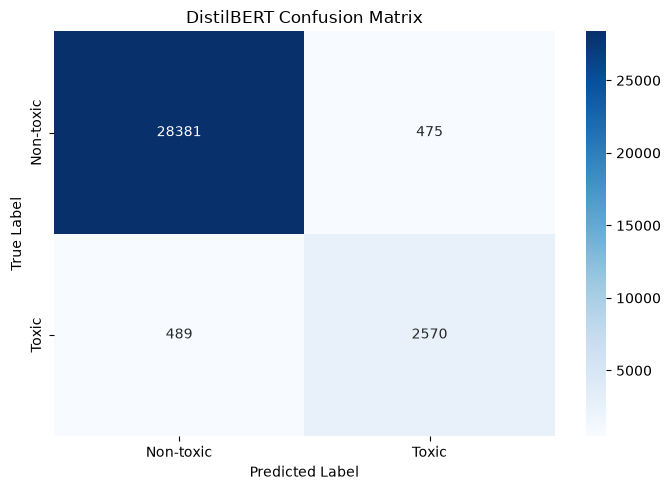

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-toxic", "Toxic"],
    yticklabels=["Non-toxic", "Toxic"]
)

plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

# Save figure
plt.savefig(
    "../results/figures/distilbert_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
print("Available prediction-related variables:")

for name in globals():
    if any(word in name.lower() for word in ["prob", "score", "logit"]):
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, value.shape)

Available prediction-related variables:


RuntimeError: dictionary changed size during iteration

In [35]:
print("Available prediction-related variables:")

variable_names = list(globals().keys())

for name in variable_names:
    if any(word in name.lower() for word in ["prob", "score", "logit"]):
        value = globals().get(name)

        if hasattr(value, "shape"):
            print(name, value.shape)

Available prediction-related variables:
logits torch.Size([8, 2])
probabilities torch.Size([3, 2])
y_prob (31915,)


In [36]:
print("y_prob type:", type(y_prob))
print("y_prob shape:", y_prob.shape)
print("First 10 probabilities:", y_prob[:10])
print("Minimum probability:", y_prob.min())
print("Maximum probability:", y_prob.max())

y_prob type: <class 'numpy.ndarray'>
y_prob shape: (31915,)
First 10 probabilities: [8.3696789e-01 3.4834514e-04 2.3264048e-04 8.8349357e-04 9.1726892e-05
 1.1914520e-04 6.1652163e-04 1.4272158e-04 3.0150186e-04 6.8310463e-01]
Minimum probability: 7.121499e-05
Maximum probability: 0.9995771


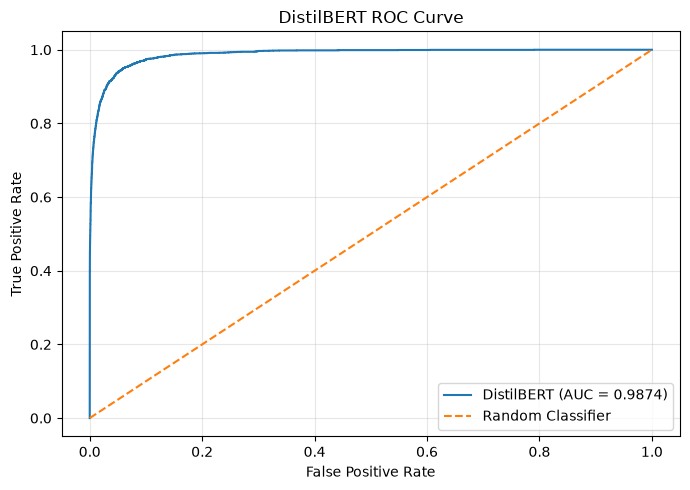

In [37]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"DistilBERT (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("DistilBERT ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/distilbert_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

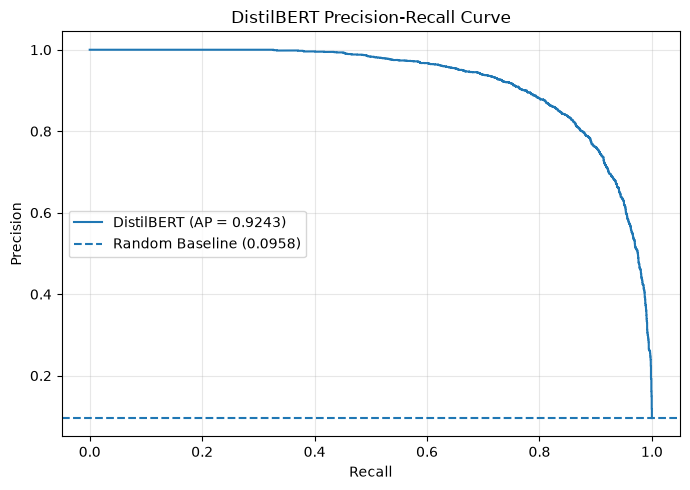

Average Precision: 0.9243252667102797


In [38]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Calculate Precision-Recall values
precision, recall, _ = precision_recall_curve(
    y_true,
    y_prob
)

# Calculate Average Precision
average_precision = average_precision_score(
    y_true,
    y_prob
)

# Positive class baseline
baseline = sum(y_true) / len(y_true)

# Plot PR Curve
plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"DistilBERT (AP = {average_precision:.4f})"
)

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Random Baseline ({baseline:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("DistilBERT Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
plt.savefig(
    "../results/figures/distilbert_pr_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Average Precision:", average_precision)

## DistilBERT Model Evaluation and Discussion

The fine-tuned DistilBERT model achieved an accuracy of 96.98% and an F1-score of 84.21% on the test dataset.

The model obtained a precision of 84.40% and a recall of 84.01%, indicating a relatively balanced ability to identify toxic comments while limiting false positive predictions.

The ROC-AUC of 0.9874 demonstrates excellent discrimination between toxic and non-toxic comments. The Average Precision of 0.9243 also indicates strong performance under the imbalanced class distribution.

Compared with TF-IDF and Word2Vec, DistilBERT achieved the highest F1-score and ROC-AUC among the three evaluated models.

However, DistilBERT requires substantially more computational resources and training time than the traditional machine learning approaches.